# Assessing the effect of window length on d2

In [1]:
%load_ext jupyter_black
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from src.analysis.prox_crit import calc_db, minimize_klr_b
from src.analysis.prox_crit_confounds import CALC_DB_DEFAULTS, plot_d2_sweep
from src.models.branching_model.branching_network import (
    distance_to_criticality,
    params_for_distance,
    bn_aa_population,
    stationary_rate_aa,
    stationary_var_aa,
)
from src.config.paths import FIGURES_DIR
from src.utils.persist import save, load, list_saves, prune
from src.utils.binning import binning
from src.utils.plotting import PET10, add_linear_inset, save_fig
from src.analysis.timescales import get_autocorrelation

PET10.use()  # default colour cycle
save_figures = True  # plots -> results/figures/prox_crit_confounds/ (sweep plots only when not debugging)

In [2]:
# define parameters
debugging = False

N = int(1e4)
R = 5
steady_rate = 0.2
seed = 123
distances = np.logspace(start=-4, stop=0, num=50, base=10)

# independent variable: window_lengths
Ts = np.logspace(start=1, stop=6, num=10, base=10).astype(int)

if debugging:
    N, R, steady_rate = int(1e3), 2, 0.2
    distances = np.logspace(start=-4, stop=0, num=8, base=10)
    Ts = np.logspace(start=2, stop=6, num=4, base=10).astype(int)

In [3]:
# generate the data
db_results = (
    []
)  # db_results[i][j][r] = DbResult for distances[i], window_lengths[j], replica r
for i, distance in enumerate(distances):
    sigma, h = params_for_distance(rate=steady_rate, distance=distance)

    results_this_distance = []
    for T in Ts:

        A = bn_aa_population(N=N, sigma=sigma, T=T, h=h, R=R, seed=seed * i)

        results_this_fuse = []
        for r in range(R):
            result = calc_db(x=A[r], **CALC_DB_DEFAULTS)
            results_this_fuse.append(result)

        results_this_distance.append(results_this_fuse)

    db_results.append(results_this_distance)
    print(f"distance {i + 1}/{len(distances)} done")

path = save(
    "bn_aa_db_T" + ("_debug" if debugging else ""),
    db_results=db_results,
    distances=distances,
    Ts=Ts,
    params=dict(N=N, T=T, R=R, steady_rate=steady_rate, seed=seed),
    keep=(
        1 if debugging else None
    ),  # debug runs: keep only the newest; real runs: keep all
)

C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit\distance.py:146: UserWarning: Error: estimated model is explosive.
  warnings.warn("Error: estimated model is explosive.")


distance 1/50 done


C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit\distance.py:146: UserWarning: Error: estimated model is explosive.
  warnings.warn("Error: estimated model is explosive.")


distance 2/50 done


C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit\distance.py:146: UserWarning: Error: estimated model is explosive.
  warnings.warn("Error: estimated model is explosive.")


distance 3/50 done


... (90 outputs left out)

C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit\distance.py:301: UserWarning: ERROR: closest critical model is explosive (optimizer left the non-explosive part of M_b).
  warnings.warn(
C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit\distance.py:146: UserWarning: Error: estimated model is explosive.
  warnings.warn("Error: estimated model is explosive.")


distance 49/50 done


C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit\distance.py:146: UserWarning: Error: estimated model is explosive.
  warnings.warn("Error: estimated model is explosive.")


distance 50/50 done
Saved data\interim\bn_aa_db_T__2026-11-20_023136.pkl (1.0 MB, git c0b24df)
  db_results : list, len 50
  distances  : ndarray float64 (50,)
  Ts         : ndarray int64 (10,)
  params     : dict, len 5
→ reload: load("bn_aa_db_T__2026-11-20_023136.pkl")  or newest of this tag: load("bn_aa_db_T")


Loaded bn_aa_db_T__2026-11-20_023136.pkl (1.0 MB, git c0b24df)
  db_results : list, len 50
  distances  : ndarray float64 (50,)
  Ts         : ndarray int64 (10,)
  params     : dict, len 5


C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit_confounds.py:45: RuntimeWarning: Mean of empty slice
  mean_over_replicas = np.nanmean(db[:, j, :], axis=1)


Saved results\figures\prox_crit_confounds\d2_vs_eps_window_length.png (958 kB, new)


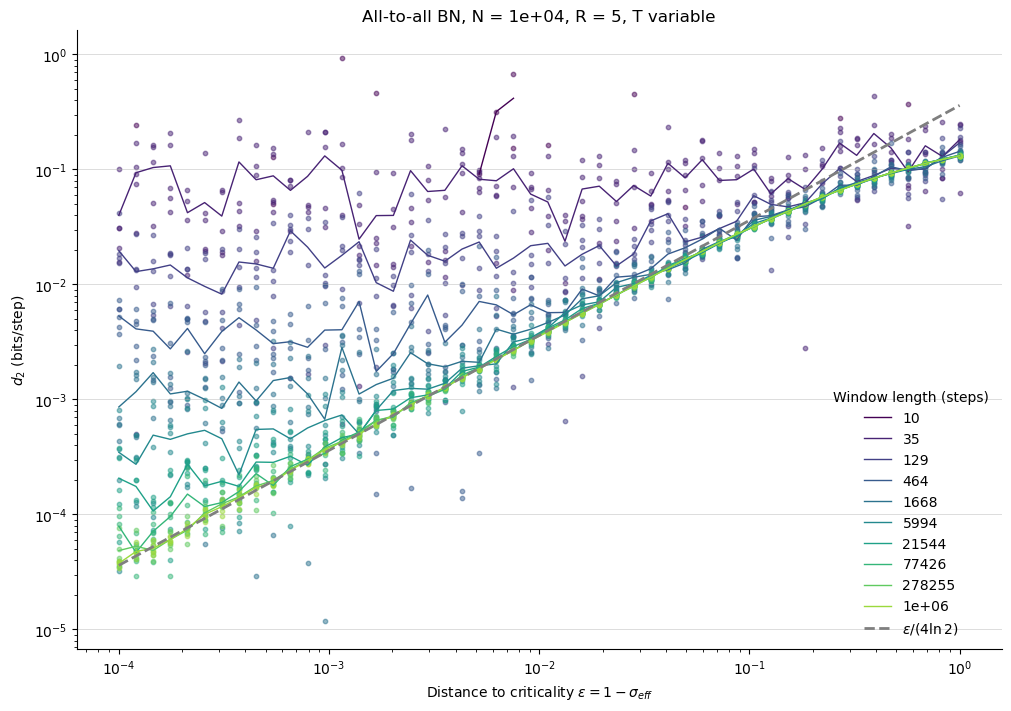

In [4]:
# plot it
data = load(
    "bn_aa_db_T" + ("_debug" if debugging else "")
)  # after a kernel restart: load("bn_aa_db_T") gets the newest run

p = data.params
fig, ax = plot_d2_sweep(
    distances=data.distances,
    db_results=data.db_results,
    values=data.Ts,
    legend_title="Window length (steps)",
    title=rf"All-to-all BN, N = {p['N']:.4g}, R = {p['R']:.4g}, T variable, b = {CALC_DB_DEFAULTS['b']}, n = {CALC_DB_DEFAULTS['order']}",
)
if save_figures and not debugging:
    save_fig(fig, "prox_crit_confounds/d2_vs_eps_window_length")
plt.show()